In [1]:
import seaborn as sns 
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split


In [2]:
titanic = sns.load_dataset("titanic")

In [3]:
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
features = ["pclass","sex","fare","embarked","age"]
target = ["survived"]

In [8]:
from sklearn.impute import SimpleImputer
imp_median = SimpleImputer(strategy = "median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]]) 
imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

In [9]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [10]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"]  = le.fit_transform(titanic["embarked"])

In [12]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,2,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,2,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,2,Third,man,True,NaN,Southampton,no,True


In [13]:
x = titanic[features]
y= titanic[target]

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)

In [15]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [16]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x_test)

In [17]:
print("Accuracy Score is:", accuracy_score(y_test, y_pred))

Accuracy Score is: 0.770949720670391


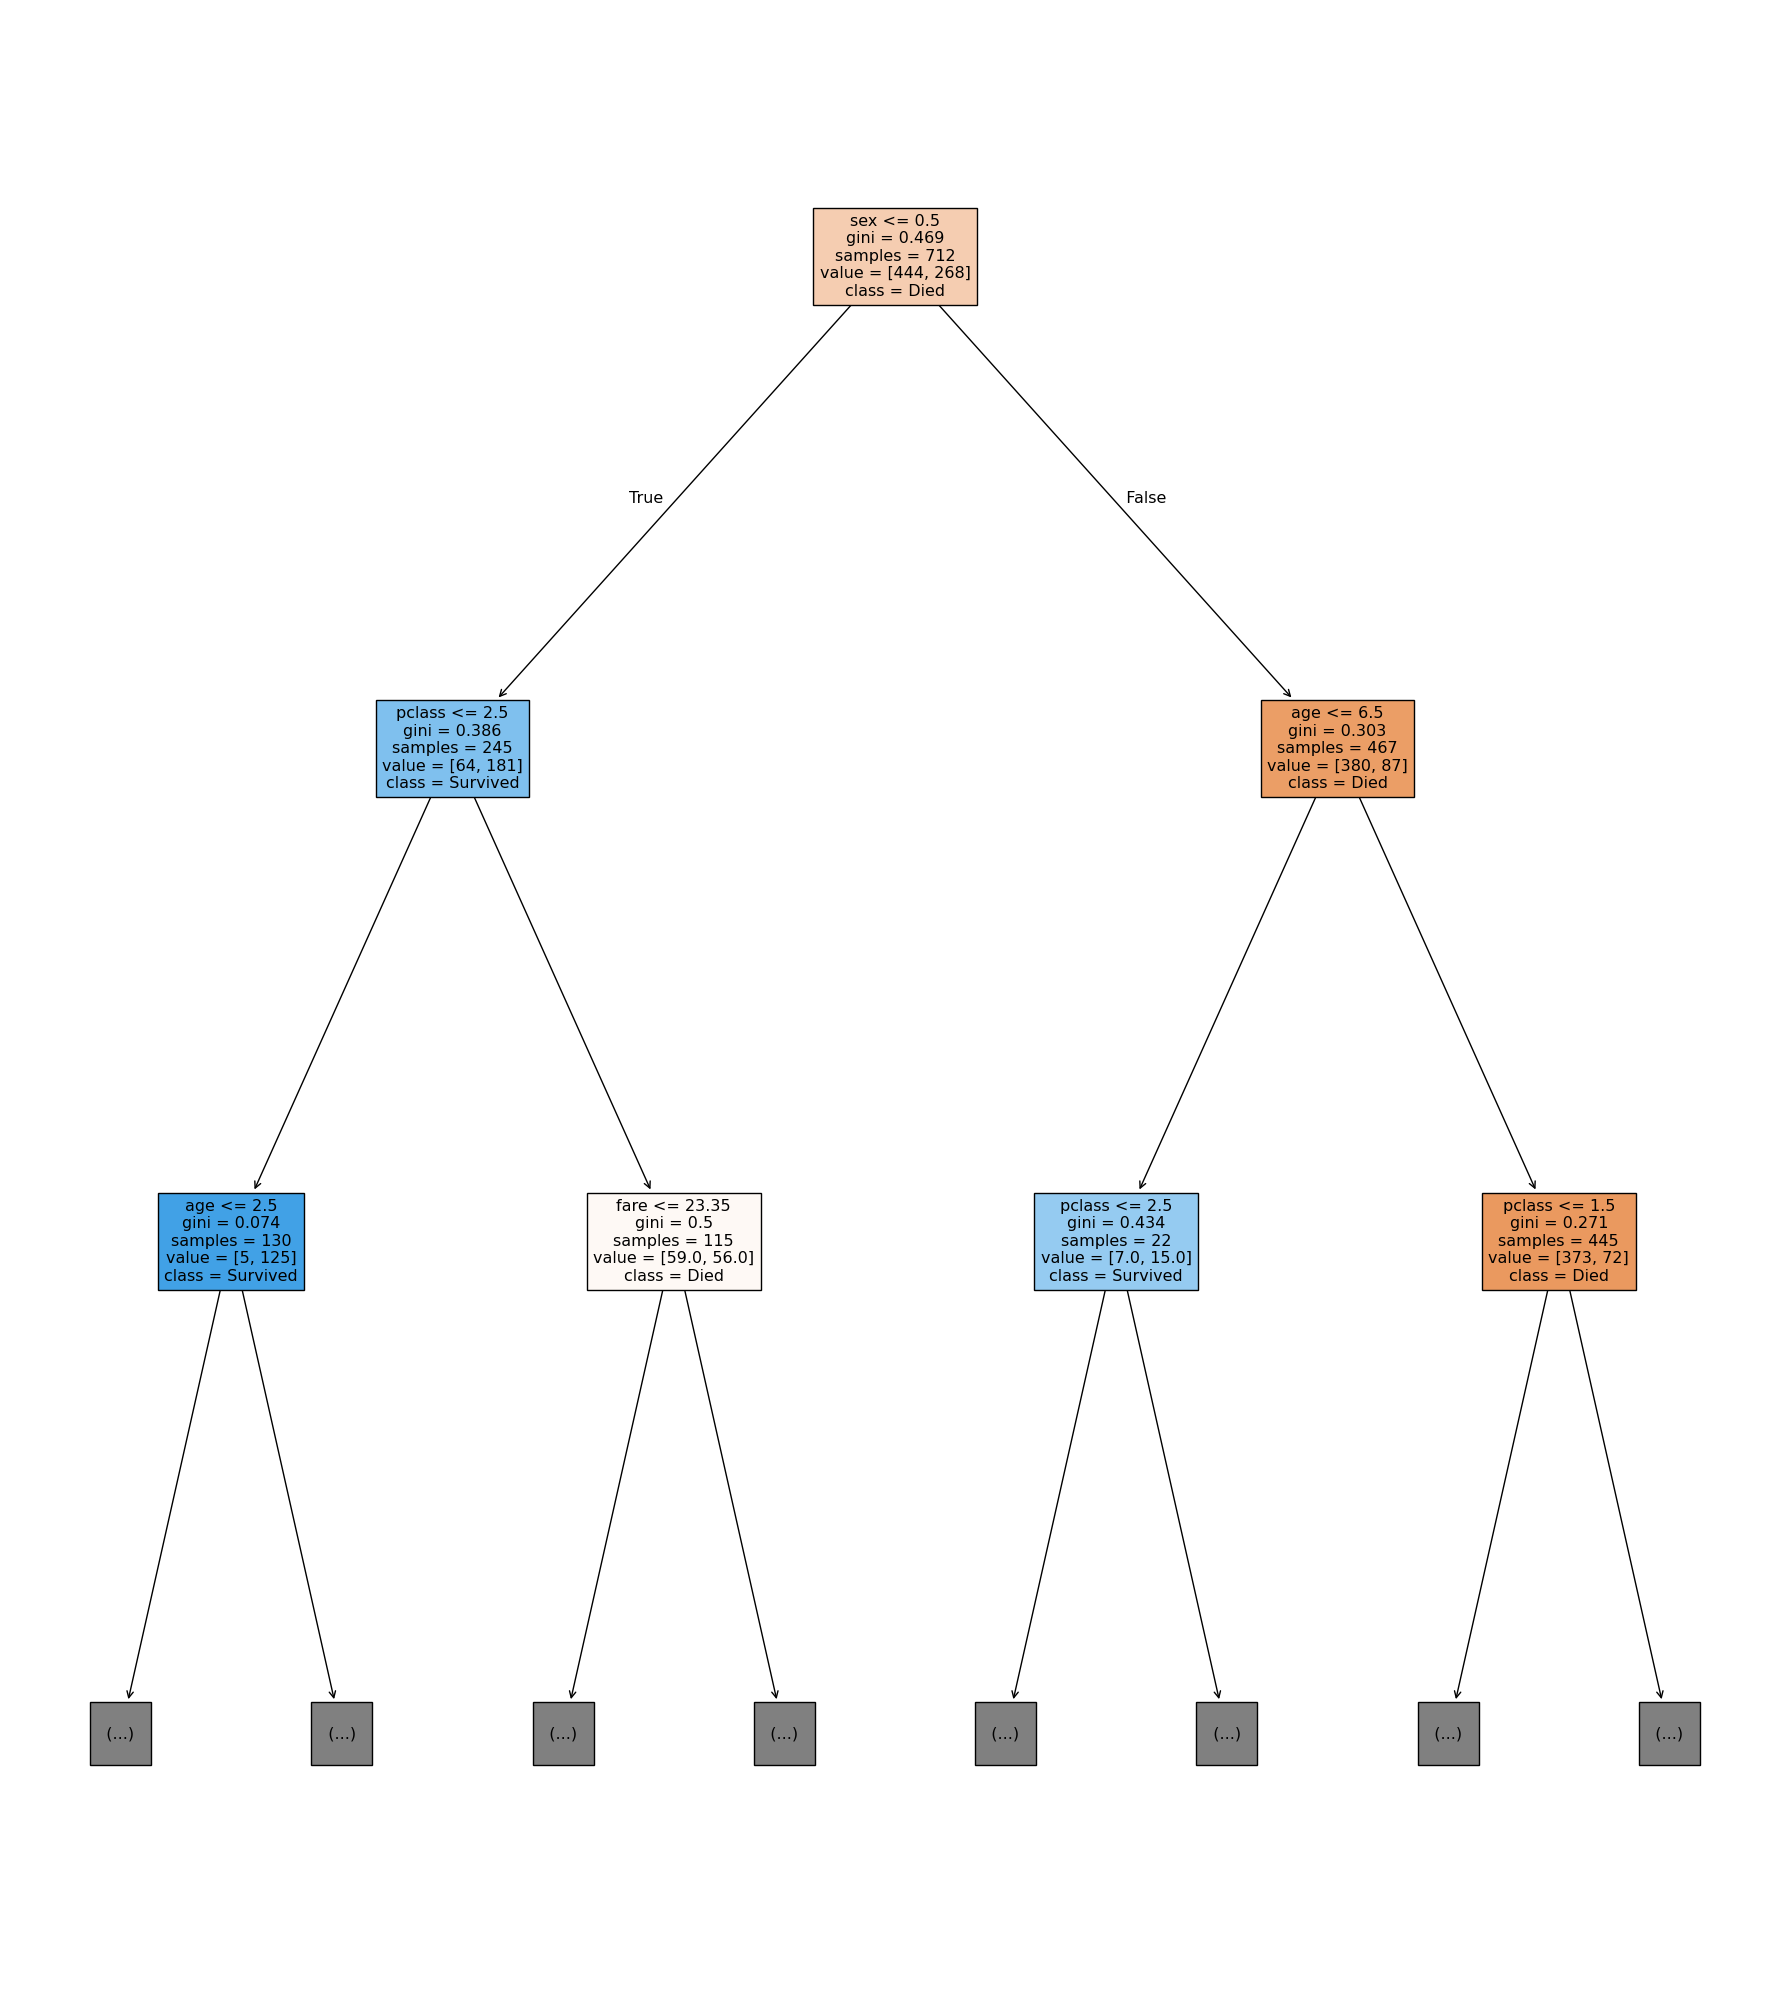

In [18]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,20))
plot_tree(
    model,
    feature_names = x.columns,
    class_names = ["Died", "Survived"],
    filled=True,
    max_depth=2
)
plt.tight_layout()

In [19]:
#Decision Tree with Pre pruning 
max_depth = [2,3,4,5,6,7,8,9,10,11]


for depth in max_depth:
    model = DecisionTreeClassifier(max_depth = depth)
    model.fit(x_train, y_train)

    acc = model.score(x_test,y_test) # Score by default use accuracy
    print(f"ffor depth={depth}, accuracy ={acc}")

ffor depth=2, accuracy =0.7653631284916201
ffor depth=3, accuracy =0.7988826815642458
ffor depth=4, accuracy =0.7988826815642458
ffor depth=5, accuracy =0.7988826815642458
ffor depth=6, accuracy =0.7988826815642458
ffor depth=7, accuracy =0.8044692737430168
ffor depth=8, accuracy =0.7988826815642458
ffor depth=9, accuracy =0.7932960893854749
ffor depth=10, accuracy =0.7988826815642458
ffor depth=11, accuracy =0.8044692737430168


In [20]:
min_samples_splits = [5,10,15,20,25]


for split in min_samples_splits:
    model = DecisionTreeClassifier(max_depth = 5, min_samples_split=split)
    model.fit(x_train, y_train)

    acc = model.score(x_test,y_test) # Score by default use accuracy
    print(f"ffor split={split}, accuracy ={acc}")

ffor split=5, accuracy =0.7988826815642458
ffor split=10, accuracy =0.7988826815642458
ffor split=15, accuracy =0.7932960893854749
ffor split=20, accuracy =0.7932960893854749
ffor split=25, accuracy =0.7877094972067039


In [21]:
# Decision Tree with Post-Pruning
full_tree = DecisionTreeClassifier(random_state=42)

full_tree.fit(x_train,y_train)



DecisionTreeClassifier(random_state=42)

In [22]:
path = full_tree.cost_complexity_pruning_path(x_train,y_train)
ccp_alphas = path.ccp_alphas
print(ccp_alphas)

[0.00000000e+00 0.00000000e+00 6.68806849e-05 1.45921494e-04
 1.84428555e-04 2.00642055e-04 2.34082397e-04 2.34082397e-04
 3.51123596e-04 4.68164794e-04 4.68164794e-04 5.61797753e-04
 6.24219725e-04 6.67991230e-04 7.02247191e-04 7.02247191e-04
 8.19288390e-04 8.19288390e-04 8.32292967e-04 8.42696629e-04
 8.42696629e-04 8.42696629e-04 8.94231048e-04 8.99610781e-04
 9.24769963e-04 9.36329588e-04 9.36329588e-04 9.36329588e-04
 9.88347898e-04 1.00253471e-03 1.05337079e-03 1.07400895e-03
 1.08038029e-03 1.11865144e-03 1.12359551e-03 1.12359551e-03
 1.13139825e-03 1.17041199e-03 1.18841832e-03 1.22566125e-03
 1.22893258e-03 1.22893258e-03 1.24361593e-03 1.24843945e-03
 1.27565833e-03 1.30996111e-03 1.33761370e-03 1.37044603e-03
 1.46301498e-03 1.47927070e-03 1.51142557e-03 1.54072312e-03
 1.56675436e-03 1.60434338e-03 1.66892062e-03 1.76144762e-03
 1.86751451e-03 2.10674157e-03 2.34082397e-03 2.41226470e-03
 2.64273538e-03 2.69412911e-03 3.43770913e-03 3.56327570e-03
 5.47433606e-03 9.055400

In [23]:
#train our model for all alphas

trees = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42,ccp_alpha=alpha)
    model.fit(x_train, y_train)
    trees.append((model,alpha))
    

In [24]:
best_acc = 0 
best_alpha = 0

for model, alpha in trees:
    curr_acc = model.score(x_test,y_test)
    if curr_acc > best_acc:
        best_acc = curr_acc
        best_alpha = alpha
    

In [25]:
best_acc

0.8379888268156425

In [26]:
best_alpha

0.0015407231242023183

In [27]:
best_model  = DecisionTreeClassifier(ccp_alpha=best_alpha)
best_model.fit(x_train,y_train)

DecisionTreeClassifier(ccp_alpha=0.0015407231242023183)

In [28]:
best_model.score(x_test,y_test)

0.8379888268156425